# Trabajo Práctico: Predicción de lluvia en Australia

**Aprendizaje Automático 1 | Tecnicatura Universitaria en Inteligencia Artificial (FCEIA, UNR)**

**Integrantes:** Franco Esparza, Franco Renna, Leandro Picó

**Objetivo:** predecir a las 23:59 de cada día si al día siguiente va a llover (`RainTomorrow`), usando las mediciones meteorológicas de ese día en 49 ciudades de Australia.

### Contenidos
**Ítem 1. Análisis descriptivo**
1. Configuración y carga de datos
2. Fuga de datos
3. Datos faltantes
4. Consistencia de los datos
5. División train / validación / test
6. Balance del dataset
7. Análisis descriptivo y visualizaciones
8. Correlación
9. Imputación de faltantes
10. Codificación de variables categóricas
11. Escalado

**Ítem 2. Regresión logística**

12. Entrenamiento de los modelos
13. Métricas
14. Matrices de confusión
15. Curva ROC y elección del umbral
16. Calidad del ajuste

---
## 1. Configuración y carga de datos

In [1]:
# Librerías y configuración general
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (mean_squared_error, accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve, auc)

import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.figsize': (12, 6), 'axes.titlesize': 13, 'axes.labelsize': 11, 'figure.dpi': 100})
sns.set_theme(style='whitegrid', palette='viridis')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)

In [2]:
# Cargamos el dataset y pasamos la fecha a tipo fecha
df = pd.read_csv('weatherAUS_2026C2.csv')
df['Date'] = pd.to_datetime(df['Date'])
TARGET = 'RainTomorrow'
COLORES = {'No': 'steelblue', 'Yes': 'darkorange'}

print(f'{df.shape[0]} filas y {df.shape[1]} columnas')
print(f'Fechas: {df["Date"].min().date()} a {df["Date"].max().date()} | Ciudades: {df["Location"].nunique()}')
print(f'Filas repetidas (misma ciudad y fecha): {df.duplicated(["Date", "Location"]).sum()}')
df.head()

145412 filas y 25 columnas
Fechas: 2007-11-01 a 2017-06-24 | Ciudades: 49
Filas repetidas (misma ciudad y fecha): 0


,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.600,22.500,0.600,NaN,NaN,W,45.000,W,WNW,19.000,25.000,68.800,23.800,1008.100,1007.200,8.000,NaN,16.800,20.800,No,No,0.000
1,1,2008-12-02,Albury,7.300,25.800,0.000,NaN,NaN,WNW,44.000,NNW,WSW,4.000,23.000,40.100,22.100,1011.100,1007.500,NaN,NaN,18.300,24.600,No,No,0.000
2,2,2008-12-03,Albury,13.200,26.200,0.000,NaN,NaN,WSW,46.000,W,WSW,20.000,27.000,36.200,31.500,1007.300,1009.400,NaN,2.000,21.200,23.400,No,No,0.000
3,3,2008-12-04,Albury,10.000,28.800,0.000,NaN,NaN,NE,23.000,SE,E,10.000,10.000,45.800,18.500,1017.600,1012.400,NaN,NaN,17.400,26.300,No,No,1.000
4,4,2008-12-05,Albury,17.400,32.400,1.000,NaN,NaN,W,41.000,ENE,NW,6.000,17.000,83.500,34.600,1010.900,1005.900,7.000,8.000,17.900,29.100,No,No,0.200


In [3]:
# Rango de las variables numéricas
df.drop(columns='Unnamed: 0').describe().T

,count,mean,min,25%,50%,75%,max,std
Date,145412,2013-04-04 08:55:50.149919,2007-11-01 00:00:00,2011-01-10 00:00:00,2013-06-02 00:00:00,2015-06-14 00:00:00,2017-06-24 00:00:00,NaN
MinTemp,143928.000,12.197,-9.700,7.600,12.000,16.900,34.100,6.418
MaxTemp,144159.000,23.223,-5.100,17.900,22.600,28.200,49.100,7.136
Rainfall,142152.000,2.362,0.000,0.000,0.000,0.800,371.000,8.479
Evaporation,82658.000,5.469,0.000,2.600,4.800,7.400,145.000,4.194
Sunshine,75616.000,7.611,0.000,4.800,8.400,10.600,14.500,3.786
WindGustSpeed,135159.000,40.037,6.000,31.000,38.000,48.000,135.000,13.648
WindSpeed9am,143645.000,14.067,0.000,7.000,13.000,19.000,130.000,8.937
WindSpeed3pm,142351.000,18.662,0.000,12.000,18.000,24.000,86.000,8.865
Humidity9am,142759.000,68.862,0.000,57.000,69.900,83.100,100.000,19.063


In [4]:
# Variables categóricas: cuántos valores distintos tienen y cuál es el más común
CATEGORICAS_ORIGINALES = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']
df[CATEGORICAS_ORIGINALES].describe().T

,count,unique,top,freq
Location,145412,49,Canberra,3435
WindGustDir,135096,16,W,9910
WindDir9am,134850,16,N,11754
WindDir3pm,141186,16,SE,10837
RainToday,142152,2,No,110276
RainTomorrow,142153,2,No,110281


Cada fila es un día en una ciudad, con las mediciones de ese día y si llovió al día siguiente.

| Variable | Qué mide | Unidad | Rango |
|---|---|---|---|
| `Date` | Fecha de la observación | | 2007-11-01 a 2017-06-24 |
| `Location` | Ciudad de la estación meteorológica | | 49 ciudades |
| `MinTemp`, `MaxTemp` | Temperatura mínima y máxima del día | °C | −9,7 a 34,1 y −5,1 a 49,1 |
| `Rainfall` | Lluvia caída en el día | mm | 0 a 371 |
| `Evaporation` | Agua evaporada en el día | mm | 0 a 145 |
| `Sunshine` | Horas de sol del día | horas | 0 a 14,5 |
| `WindGustDir`, `WindGustSpeed` | Dirección y velocidad de la ráfaga más fuerte | 16 direcciones, km/h | 6 a 135 km/h |
| `WindDir9am`, `WindDir3pm` | Dirección del viento a las 9 y a las 15 | 16 direcciones | |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad del viento a las 9 y a las 15 | km/h | 0 a 130 y 0 a 86 |
| `Humidity9am`, `Humidity3pm` | Humedad relativa a las 9 y a las 15 | % | 0 a 100 |
| `Pressure9am`, `Pressure3pm` | Presión atmosférica a las 9 y a las 15 | hPa | 977 a 1041 |
| `Cloud9am`, `Cloud3pm` | Parte del cielo cubierta por nubes | octas (0 despejado, 8 cubierto) | 0 a 9 |
| `Temp9am`, `Temp3pm` | Temperatura a las 9 y a las 15 | °C | −8 a 39,8 y −5,8 a 47 |
| `RainToday` | Si llovió hoy (más de 1 mm) | Yes / No | |
| **`RainTomorrow`** | **Target: si mañana llueve (más de 1 mm)** | Yes / No | |
| `RainfallTomorrow` | Lluvia caída al día siguiente | mm | 0 a 371 |
| `Unnamed: 0` | Número de fila del archivo | | |

Hay 16 variables numéricas medidas en el día, 4 categóricas (ciudad y las tres direcciones de viento), `RainToday` y el target. El comportamiento de cada una se analiza en la sección 7.

---
## 2. Fuga de datos

La predicción se hace a las 23:59, así que solo podemos usar lo que se conoce hasta ese momento. `RainfallTomorrow` es la lluvia de mañana: revisamos qué relación tiene con el target.

In [5]:
# RainfallTomorrow contra el target y contra la lluvia del día siguiente en la misma ciudad
con_dato = df[df[TARGET].notna() & df['RainfallTomorrow'].notna()]
coincide = ((con_dato['RainfallTomorrow'] > 1) == (con_dato[TARGET] == 'Yes')).mean()
print(f'RainTomorrow es "Yes" exactamente cuando RainfallTomorrow > 1 mm: {coincide * 100:.2f}% de las filas')

orden = df.sort_values(['Location', 'Date'])
lluvia_dia_siguiente = orden.groupby('Location')['Rainfall'].shift(-1)
comparables = lluvia_dia_siguiente.notna() & orden['RainfallTomorrow'].notna()
iguales = (lluvia_dia_siguiente[comparables] == orden.loc[comparables, 'RainfallTomorrow']).mean()
print(f'RainfallTomorrow igual al Rainfall del día siguiente en la misma ciudad: {iguales * 100:.2f}%')

RainTomorrow es "Yes" exactamente cuando RainfallTomorrow > 1 mm: 100.00% de las filas
RainfallTomorrow igual al Rainfall del día siguiente en la misma ciudad: 100.00%


`RainfallTomorrow` es el `Rainfall` del día siguiente, copiado en la fila de hoy, y define el target por completo. A las 23:59 ese dato todavía no existe, y si lo dejamos el modelo acierta el 100% sin aprender nada, así que la eliminamos. También sacamos `Unnamed: 0`, que es solo el número de fila.

In [6]:
# Sacamos la columna con información del futuro y el número de fila
df = df.drop(columns=['RainfallTomorrow', 'Unnamed: 0'])
df.shape

(145412, 23)

---
## 3. Datos faltantes

In [7]:
# Reporte de valores nulos por columna
nulos = df.isnull().sum()
reporte_nulos = pd.DataFrame({'Nulos': nulos, 'Porcentaje (%)': nulos / len(df) * 100})
reporte_nulos.sort_values('Nulos', ascending=False)

,Nulos,Porcentaje (%)
Sunshine,69796,47.999
Evaporation,62754,43.156
Cloud3pm,59336,40.805
Cloud9am,55870,38.422
Pressure9am,15061,10.357
Pressure3pm,15024,10.332
WindDir9am,10562,7.263
WindGustDir,10316,7.094
WindGustSpeed,10253,7.051
Humidity3pm,4505,3.098


In [8]:
# Faltantes por fila
nulos_por_fila = df.isna().sum(axis=1)
print(f'Filas completas: {(nulos_por_fila == 0).sum()} ({(nulos_por_fila == 0).mean() * 100:.1f}%)')
print(f'Filas sin el target: {df[TARGET].isna().sum()} ({df[TARGET].isna().mean() * 100:.2f}%)')

Filas completas: 56412 (38.8%)
Filas sin el target: 3259 (2.24%)


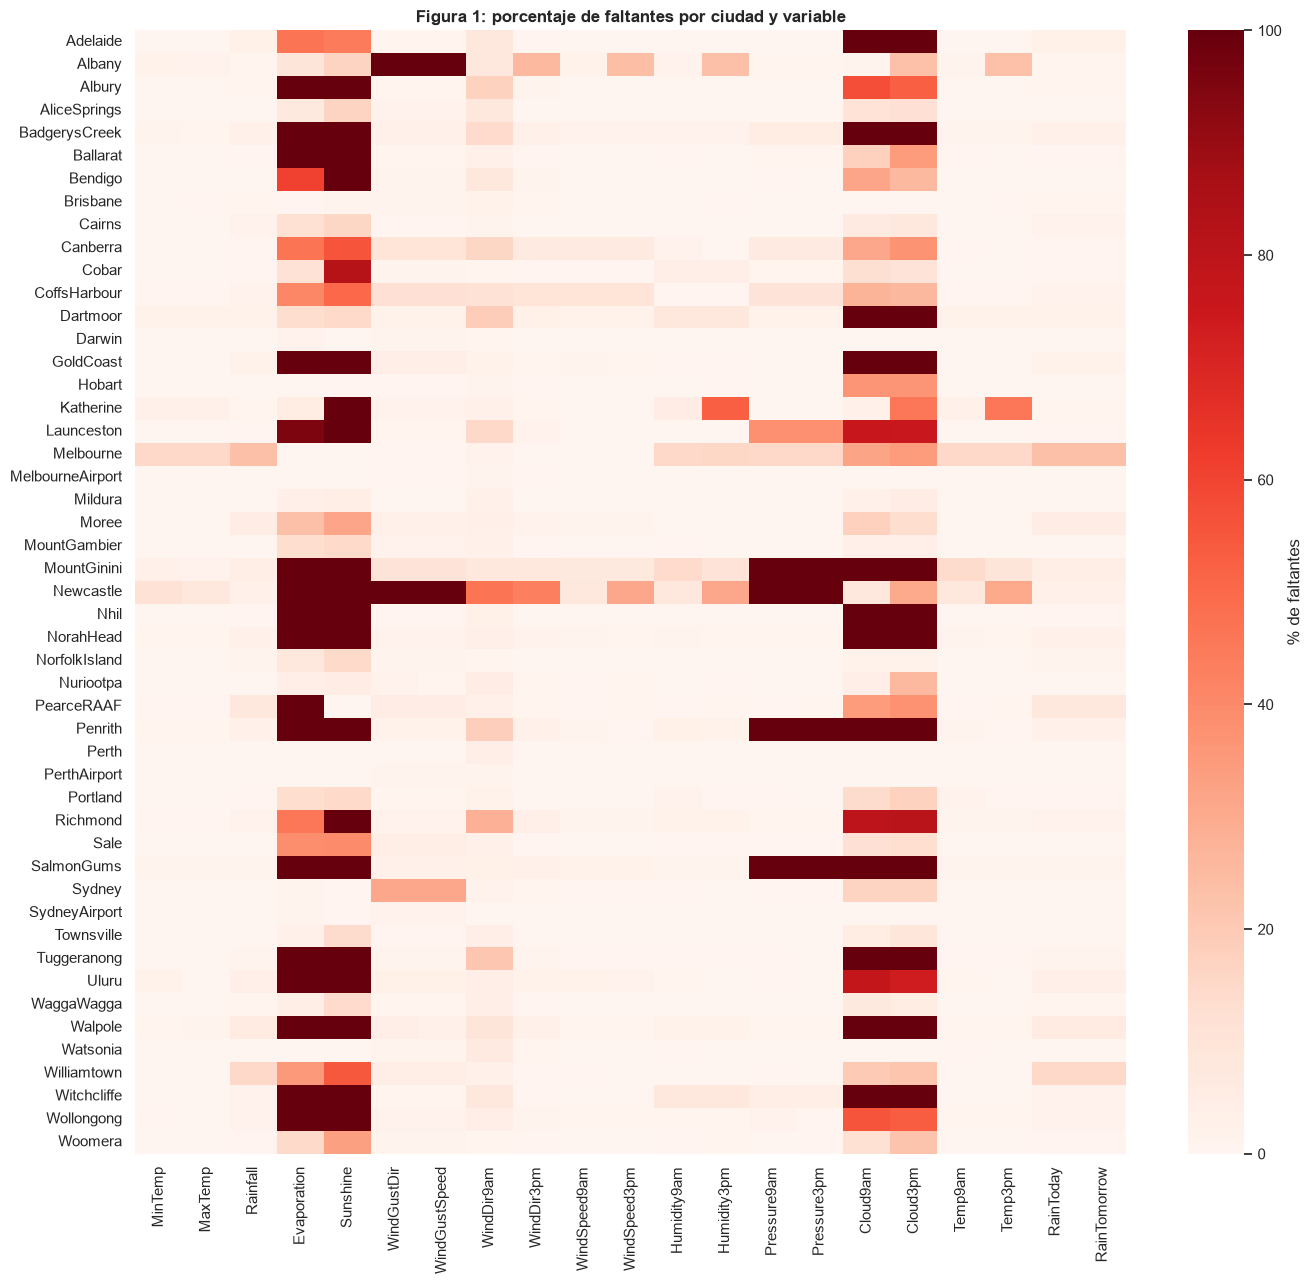

In [9]:
# Figura 1: porcentaje de faltantes de cada variable en cada ciudad
faltantes_ciudad = df.drop(columns=['Date', 'Location']).isna().groupby(df['Location']).mean() * 100

fig, ax = plt.subplots(figsize=(14, 13))
sns.heatmap(faltantes_ciudad, cmap='Reds', vmin=0, vmax=100, cbar_kws={'label': '% de faltantes'}, ax=ax)
ax.set_title('Figura 1: porcentaje de faltantes por ciudad y variable', fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [10]:
# Cantidad de ciudades que no registran nunca cada variable
nunca = (faltantes_ciudad == 100).sum()
nunca[nunca > 0].to_frame('Ciudades sin ningún dato').T

,Evaporation,Sunshine,WindGustDir,WindGustSpeed,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm
Ciudades sin ningún dato,16,19,2,2,4,4,12,12


Los faltantes no están repartidos al azar. Solo el 38,8% de las filas está completa, y en la Figura 1 se ve que las variables con más faltantes (`Sunshine`, `Evaporation`, `Cloud9am` y `Cloud3pm`) faltan por ciudad: hay estaciones que directamente no las miden. 19 ciudades no tienen ningún dato de `Sunshine`, 16 de `Evaporation` y 12 de nubosidad. Como el faltante depende de la ciudad, que es un dato que sí tenemos, el mecanismo es MAR, y eso permite completarlos a partir de las demás variables.

Decisiones:
- No eliminamos filas con faltantes, porque perderíamos el 61% de los datos. Tampoco sacamos las columnas con muchos faltantes sin antes ver si sirven para predecir (sección 8).
- Las 3259 filas sin `RainTomorrow` (2,24%) sí se eliminan: sin la respuesta no sirven para entrenar ni para evaluar, e imputarla sería inventarla.
- El resto se imputa en la sección 9, después de dividir los datos.

In [11]:
# Eliminamos las filas sin target
filas_antes = len(df)
df = df[df[TARGET].notna()].reset_index(drop=True)
print(f'Eliminadas: {filas_antes - len(df)} filas ({(filas_antes - len(df)) / filas_antes * 100:.2f}%) -> quedan {len(df)}')

Eliminadas: 3259 filas (2.24%) -> quedan 142153


---
## 4. Consistencia de los datos

In [12]:
# Controles de rango y de coherencia entre variables
min_mayor = df['MinTemp'] > df['MaxTemp']
print(f'Filas con MinTemp > MaxTemp: {min_mayor.sum()} (diferencia media {(df["MinTemp"] - df["MaxTemp"])[min_mayor].mean():.2f} °C)')
print(f'Nubosidad mayor a 8 octas: {(df[["Cloud9am", "Cloud3pm"]] > 8).sum().sum()}')
print(f'Humedad fuera de 0-100: {((df[["Humidity9am", "Humidity3pm"]] < 0) | (df[["Humidity9am", "Humidity3pm"]] > 100)).sum().sum()}')
print(f'Lluvia o evaporación negativas: {(df[["Rainfall", "Evaporation"]] < 0).sum().sum()}')

lluvia = df[['Rainfall', 'RainToday']].dropna()
print(f'Filas donde RainToday no coincide con Rainfall > 1 mm: {((lluvia["Rainfall"] > 1) != (lluvia["RainToday"] == "Yes")).sum()}')

Filas con MinTemp > MaxTemp: 68 (diferencia media 0.40 °C)
Nubosidad mayor a 8 octas: 3
Humedad fuera de 0-100: 0
Lluvia o evaporación negativas: 0
Filas donde RainToday no coincide con Rainfall > 1 mm: 0


- Hay 68 filas con `MinTemp` mayor que `MaxTemp`, con una diferencia media de 0,4 °C. Investigamos el dataset en la web, y encontramos que la mínima se mide en las 24 horas hasta las 9 am y la máxima en las 24 horas desde las 9 am, así que puede pasar sin ser un error. Las dejamos.
- Tres valores de nubosidad valen 9. Las octas van de 0 a 8, así que no es un valor posible: los pasamos a faltante y se imputan con el resto.
- `RainToday` coincide siempre con que `Rainfall` sea mayor a 1 mm. Después de imputar vamos a recalcular `RainToday` a partir de la lluvia, para que las dos queden coherentes.

In [13]:
# La nubosidad va de 0 a 8 octas: el 9 no es un valor posible y lo pasamos a faltante
for col in ['Cloud9am', 'Cloud3pm']:
    df.loc[df[col] > 8, col] = np.nan

---
## 5. División train / validación / test

Los datos son una serie de tiempo: cada ciudad tiene un registro por día. Si dividimos al azar, el modelo entrena con días posteriores a los que después usamos para evaluarlo, y además días vecinos (muy parecidos entre sí) quedan repartidos entre train y test. Eso no pasa en el uso real, donde siempre predecimos con lo que ya ocurrió. Por eso cortamos por fecha, entrenando con el pasado y evaluando con lo más reciente.

Dividimos acá, antes de imputar, codificar o escalar, para que nada de eso se calcule mirando validación o test.

In [14]:
# División temporal: train hasta 2014, validación 2015 y test desde 2016
CORTE_VAL, CORTE_TEST = '2015-01-01', '2016-01-01'
train = df[df['Date'] < CORTE_VAL].copy()
val = df[(df['Date'] >= CORTE_VAL) & (df['Date'] < CORTE_TEST)].copy()
test = df[df['Date'] >= CORTE_TEST].copy()

conjuntos = {'Train': train, 'Validación': val, 'Test': test}
pd.DataFrame({
    'Desde': [d['Date'].min().date() for d in conjuntos.values()],
    'Hasta': [d['Date'].max().date() for d in conjuntos.values()],
    'Filas': [len(d) for d in conjuntos.values()],
    '% de filas': [len(d) / len(df) * 100 for d in conjuntos.values()],
    '% llueve mañana': [(d[TARGET] == 'Yes').mean() * 100 for d in conjuntos.values()],
    'Ciudades': [d['Location'].nunique() for d in conjuntos.values()],
}, index=list(conjuntos)).round(1)

,Desde,Hasta,Filas,% de filas,% llueve mañana,Ciudades
Train,2007-11-01,2014-12-31,98988,69.600,22.500,49
Validación,2015-01-01,2015-12-31,17231,12.100,21.200,49
Test,2016-01-01,2017-06-24,25934,18.200,22.900,49


Train va hasta 2014 (69,6% de las filas), validación es todo 2015 (12,1%) y test va desde 2016 (18,2%). Usamos años completos para que validación tenga todas las estaciones del año. Las 49 ciudades están en los tres conjuntos y la proporción de días con lluvia es parecida (22,5%, 21,2% y 22,9%).

Validación se usa para elegir el umbral de decisión de la regresión logística (ítem 2) y más adelante los hiperparámetros, sin tocar test.

In [15]:
# Porcentaje de faltantes en cada conjunto, para las variables donde más cambia entre train y test
faltantes_conjunto = pd.DataFrame({nombre: d.isna().mean() * 100 for nombre, d in conjuntos.items()})
faltantes_conjunto[faltantes_conjunto['Test'] - faltantes_conjunto['Train'] > 2].sort_values('Test', ascending=False).round(1)

,Train,Validación,Test
Sunshine,41.100,53.200,69.100
Evaporation,37.500,49.100,58.800
Cloud3pm,37.100,40.700,51.200
Cloud9am,36.100,38.300,43.500
Humidity3pm,1.200,3.900,6.800
Temp3pm,0.700,2.800,6.100
WindDir3pm,2.100,3.000,4.700
WindSpeed3pm,1.200,2.100,4.300


Los faltantes aumentan con el tiempo: `Sunshine` falta en el 41% de train, el 53% de validación y el 69% de test, y pasa algo parecido con `Evaporation` y la nubosidad. En test vamos a tener más valores imputados que en train, y eso puede bajar el rendimiento del modelo. Con un split al azar esto no se hubiera visto. Lo tenemos en cuenta al leer los resultados.

---
## 6. Balance del dataset

In [16]:
# Cantidad de días con y sin lluvia al día siguiente en train
balance = train[TARGET].value_counts()
pd.DataFrame({'Días': balance, '%': balance / len(train) * 100}).round(1)

,Días,%
RainTomorrow,,
No,76705,77.500
Yes,22283,22.500


In [17]:
# Qué pasaría con un modelo que dice siempre "No"
for nombre, d in conjuntos.items():
    print(f'{nombre}: accuracy {(d[TARGET] == "No").mean() * 100:.1f}% | días de lluvia detectados: 0 de {(d[TARGET] == "Yes").sum()}')

Train: accuracy 77.5% | días de lluvia detectados: 0 de 22283
Validación: accuracy 78.8% | días de lluvia detectados: 0 de 3648
Test: accuracy 77.1% | días de lluvia detectados: 0 de 5941


El dataset no está balanceado: en train el 77,5% de los días no llueve al día siguiente y el 22,5% sí, más de 3 a 1.

Un modelo que dice siempre "No" tiene 77,5% de accuracy en train y 77,1% en test sin detectar ni un día de lluvia. Con datos así la accuracy sola engaña, y hay que mirar métricas de la clase "Yes", como el recall y la precisión (ítem 2). Además el modelo tiende a favorecer a la clase mayoritaria, por eso en el ítem 2 probamos también una versión que le da más peso a los días de lluvia.

---
## 7. Análisis descriptivo y visualizaciones

Todo el análisis de esta sección se hace sobre train.

In [18]:
# Variables numéricas y estadísticos en train
NUMERICAS = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed',
             'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am',
             'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
train[NUMERICAS].describe().T

,count,mean,std,min,25%,50%,75%,max
MinTemp,98554.000,12.001,6.367,-9.700,7.500,11.800,16.600,34.100
MaxTemp,98790.000,23.004,7.009,-3.900,17.800,22.400,27.900,49.100
Rainfall,97988.000,2.373,8.519,0.000,0.000,0.000,0.800,371.000
Evaporation,61878.000,5.287,3.951,0.000,2.600,4.600,7.200,82.400
Sunshine,58292.000,7.602,3.788,0.000,4.800,8.400,10.600,14.300
WindGustSpeed,92086.000,40.230,13.755,6.000,31.000,38.000,48.000,135.000
WindSpeed9am,97855.000,14.127,9.015,0.000,7.000,13.000,20.000,88.000
WindSpeed3pm,97848.000,18.767,8.932,0.000,12.000,18.000,24.000,86.000
Humidity9am,97723.000,68.642,19.024,0.000,56.800,69.600,82.800,100.000
Humidity3pm,97802.000,51.494,20.789,0.000,36.700,51.900,65.700,100.000


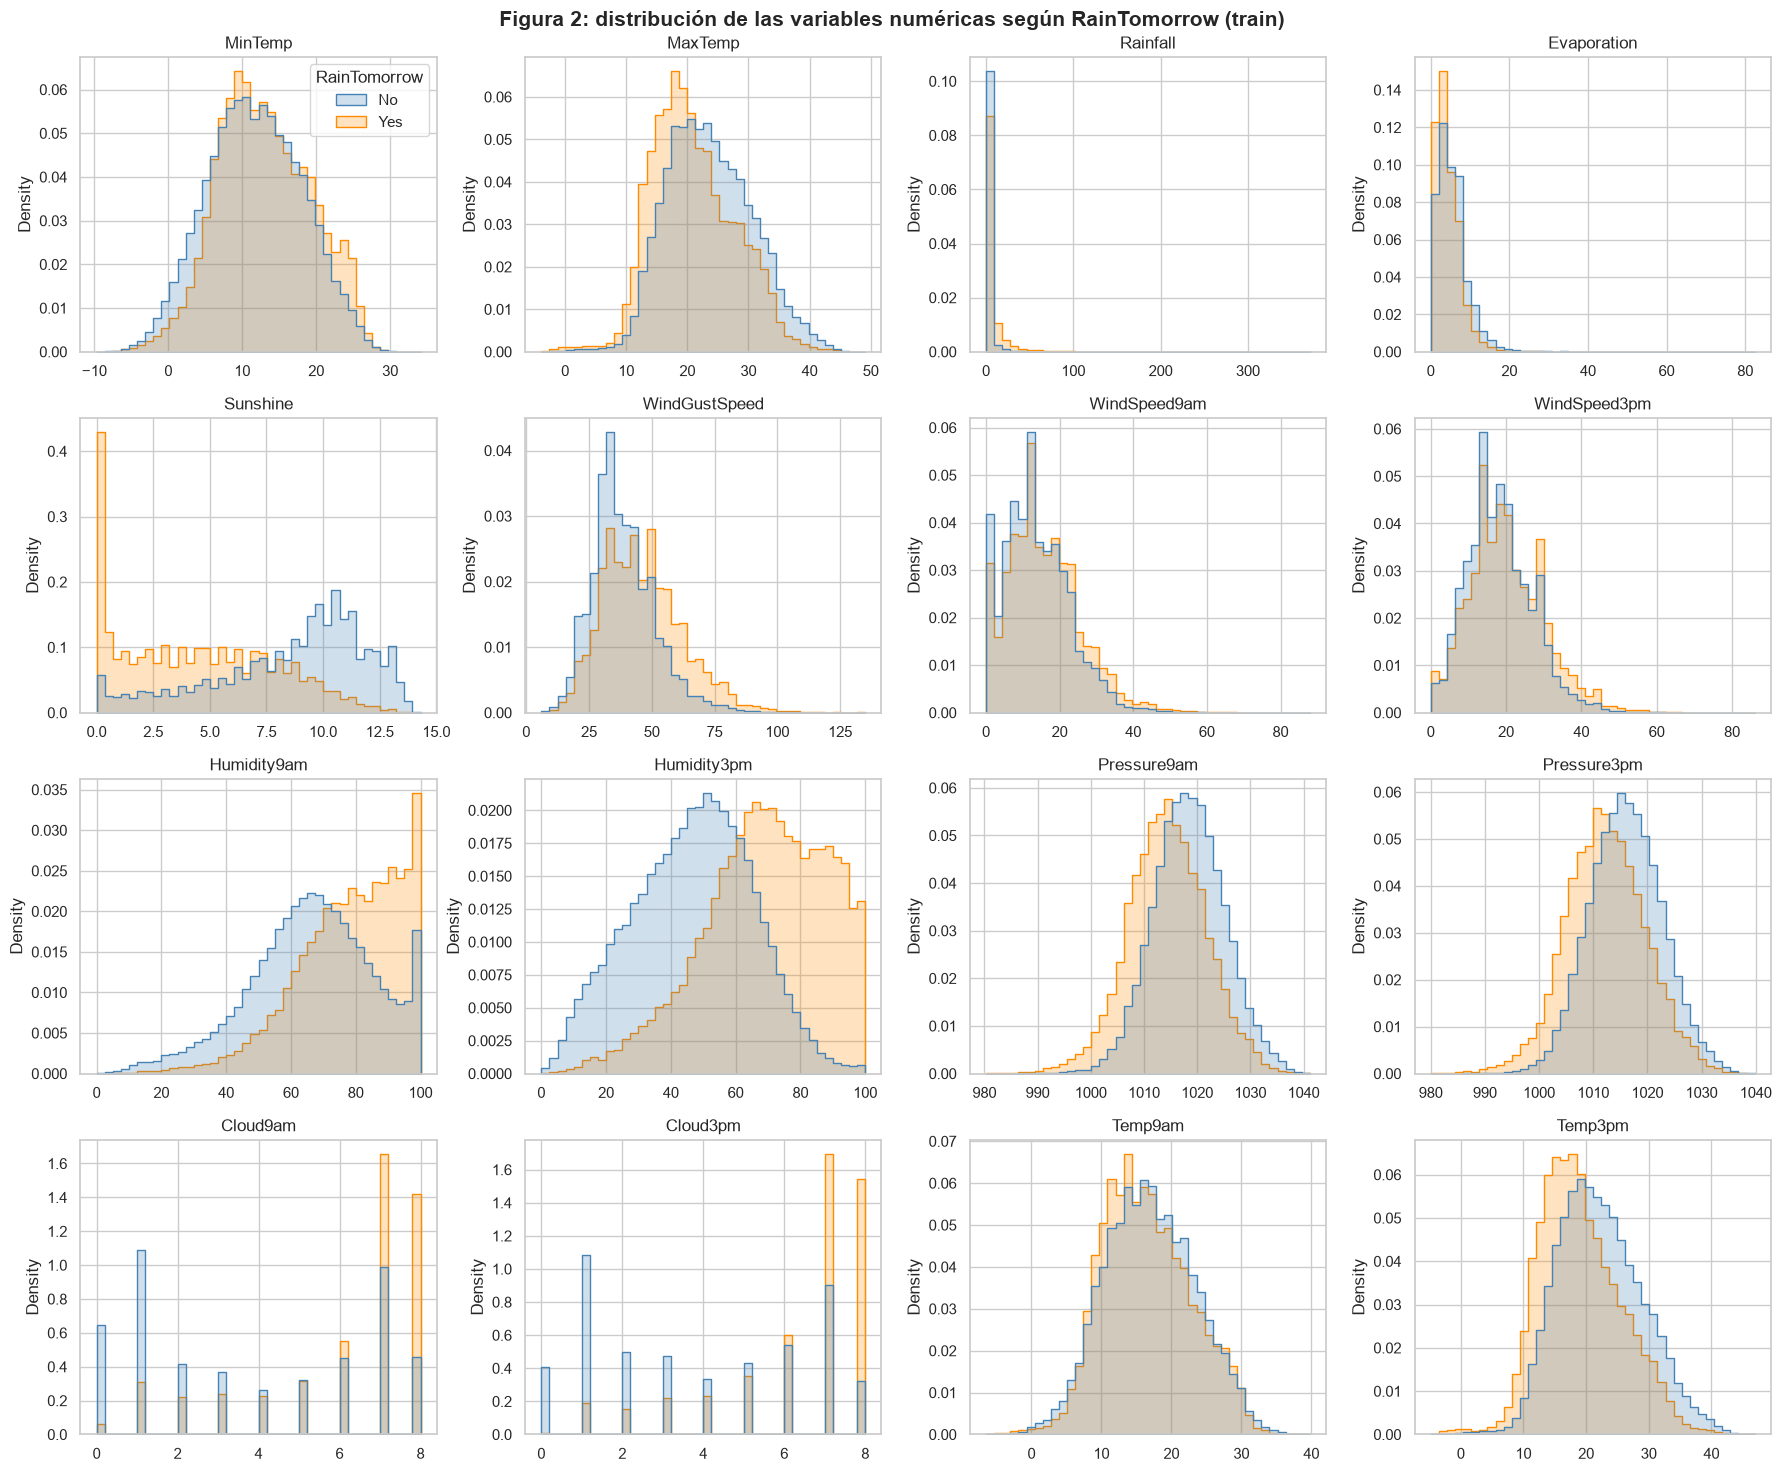

In [19]:
# Figura 2: distribución de cada variable según si llueve o no al día siguiente
fig, axes = plt.subplots(4, 4, figsize=(18, 15))
for i, (ax, col) in enumerate(zip(axes.flat, NUMERICAS)):
    sns.histplot(data=train, x=col, hue=TARGET, hue_order=['No', 'Yes'], palette=COLORES, stat='density',
                 common_norm=False, bins=40, element='step', ax=ax, legend=(i == 0))
    ax.set_title(col)
    ax.set_xlabel('')
fig.suptitle('Figura 2: distribución de las variables numéricas según RainTomorrow (train)', fontweight='bold', fontsize=15)
plt.tight_layout()
plt.show()

Figura 2:
- Las que más separan las dos clases son `Humidity3pm`, `Sunshine` y la nubosidad. Antes de un día de lluvia la humedad de la tarde suele ser alta (entre 60 y 100%), hay pocas horas de sol (se acumulan cerca de 0) y el cielo está casi cubierto (7 u 8 octas). Los días sin lluvia al día siguiente tienen humedad media, 9 a 12 horas de sol y cielo más despejado.
- La presión también separa, aunque menos: antes de un día de lluvia es un poco más baja.
- `MinTemp`, `Temp9am` y las velocidades del viento se superponen casi por completo: solas dicen poco.
- `Rainfall` y `Evaporation` son muy asimétricas, con la mayoría de los días en 0 o cerca y una cola larga de valores altos.
- La nubosidad solo toma valores enteros de 0 a 8.

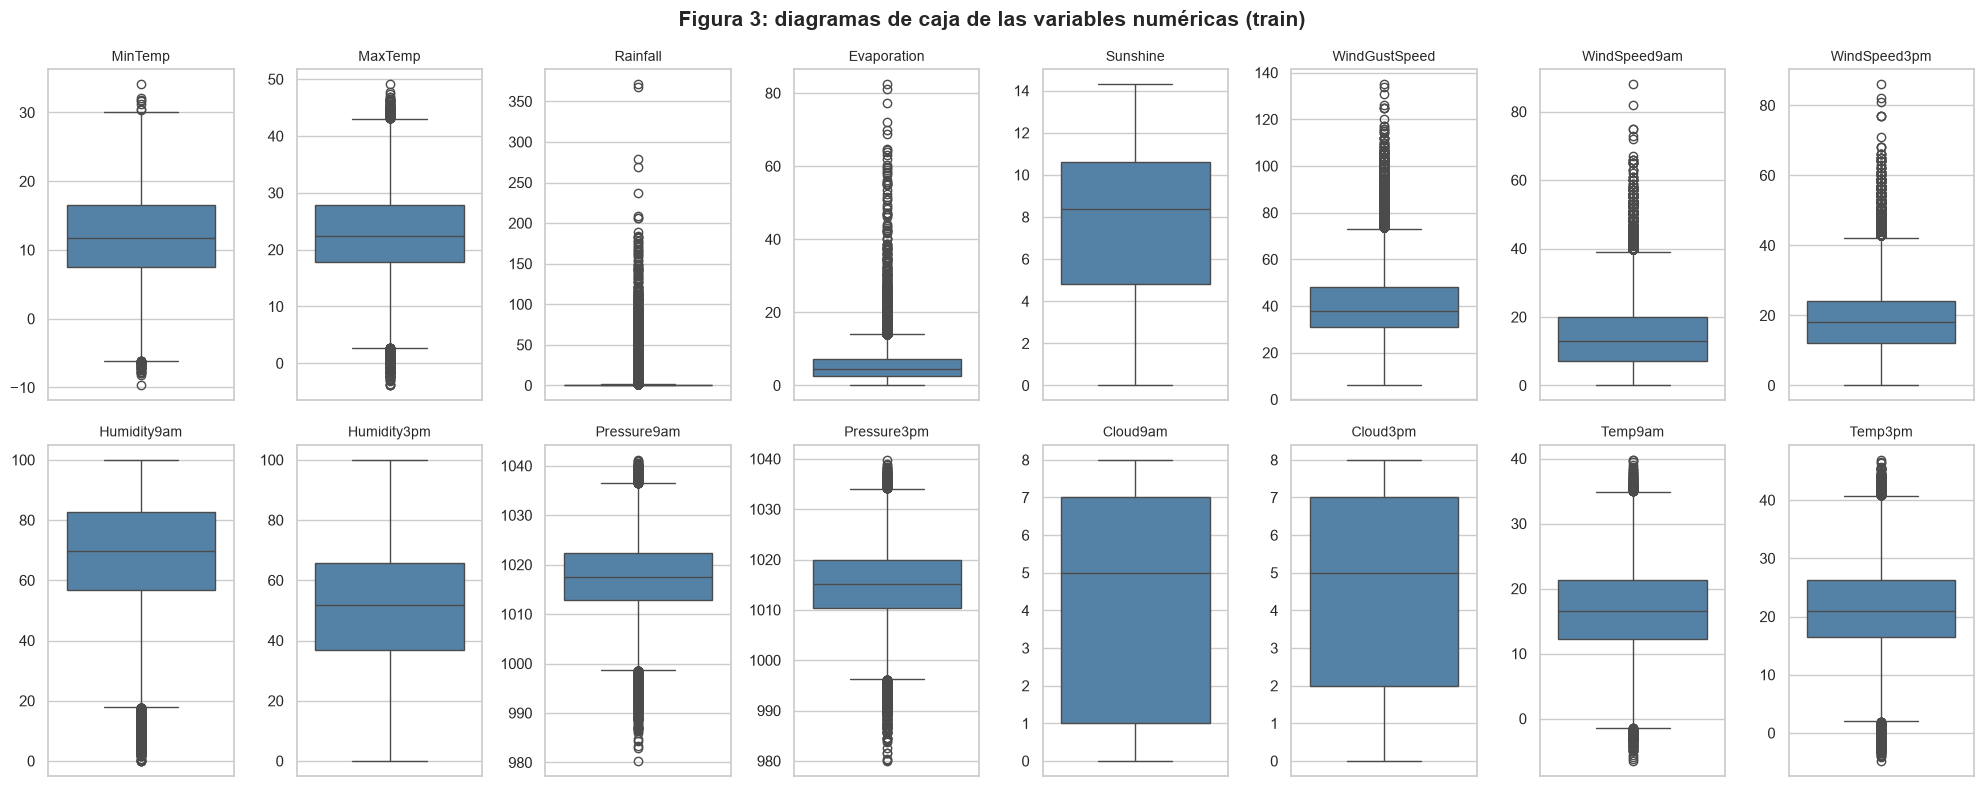

In [20]:
# Figura 3: diagramas de caja de las variables numéricas
fig, axes = plt.subplots(2, 8, figsize=(20, 8))
for ax, col in zip(axes.flat, NUMERICAS):
    sns.boxplot(y=train[col], ax=ax, color='steelblue')
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('')
fig.suptitle('Figura 3: diagramas de caja de las variables numéricas (train)', fontweight='bold', fontsize=15)
plt.tight_layout()
plt.show()

In [21]:
# Porcentaje de outliers de cada variable según el criterio del rango intercuartil
IQR_FACTOR = 1.5
reporte_outliers = []
for col in NUMERICAS:
    datos = train[col].dropna()
    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    iqr = q3 - q1
    outliers_iqr = ((datos < q1 - IQR_FACTOR * iqr) | (datos > q3 + IQR_FACTOR * iqr)).sum()
    reporte_outliers.append({'Variable': col, 'Outliers': outliers_iqr, '% de los datos': outliers_iqr / len(datos) * 100})

df_outliers = pd.DataFrame(reporte_outliers).set_index('Variable')
df_outliers[df_outliers['Outliers'] > 0].sort_values('Outliers', ascending=False).round(2).T

Variable,Rainfall,WindGustSpeed,Evaporation,WindSpeed3pm,WindSpeed9am,Humidity9am,Pressure9am,Pressure3pm,Temp3pm,MaxTemp,Temp9am,MinTemp
Outliers,17677.000,2149.000,1619.000,1201.000,1089.000,1074.000,807.000,673.000,580.000,437.000,221.000,43.000
% de los datos,18.040,2.330,2.620,1.230,1.110,1.100,0.900,0.750,0.590,0.440,0.230,0.040


Figura 3 y tabla de outliers: `Rainfall` es la que más outliers tiene (18% de los días), porque casi siempre llueve 0 o poco y cualquier lluvia fuerte queda fuera del rango. Le siguen la evaporación y las velocidades del viento, con entre 1 y 3%. Son valores posibles (tormentas, ráfagas, días muy secos) y los días de mucha lluvia son los que más nos interesan, así que no eliminamos outliers.

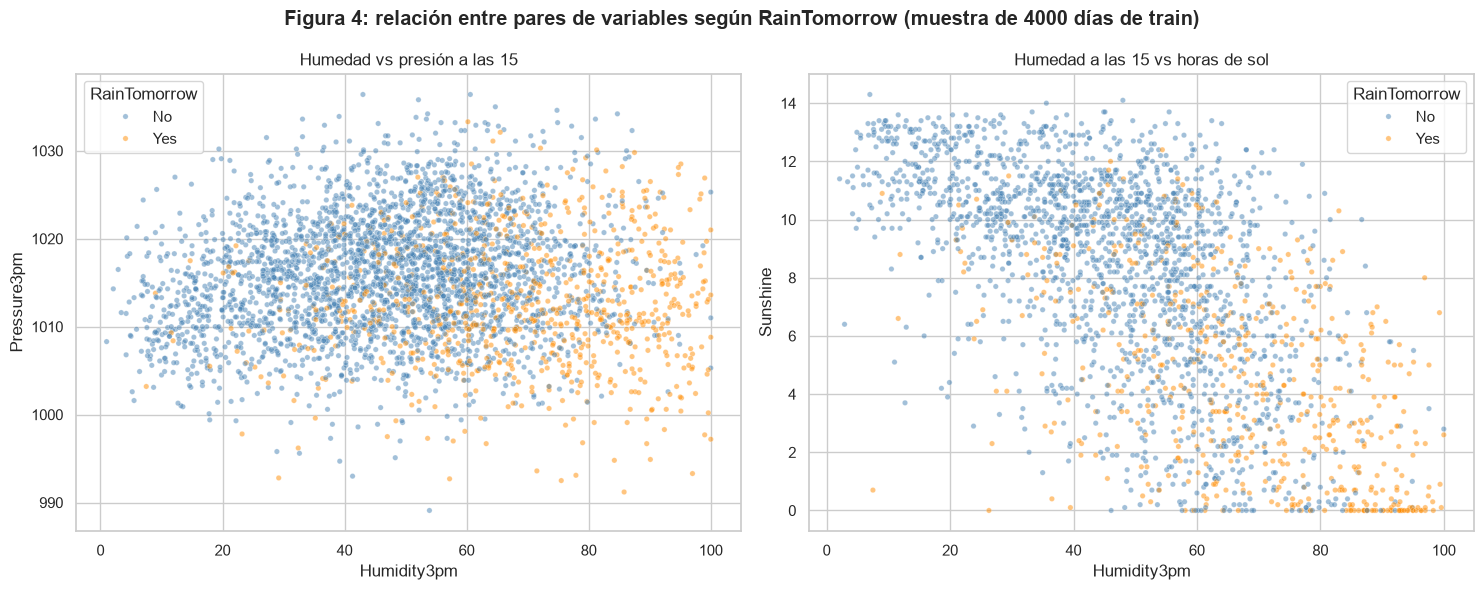

In [22]:
# Figura 4: pares de variables coloreados por el target, sobre una muestra para que se vean los puntos
muestra = train.sample(4000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=muestra, x='Humidity3pm', y='Pressure3pm', hue=TARGET, hue_order=['No', 'Yes'], palette=COLORES, alpha=0.5, s=15, ax=axes[0])
sns.scatterplot(data=muestra, x='Humidity3pm', y='Sunshine', hue=TARGET, hue_order=['No', 'Yes'], palette=COLORES, alpha=0.5, s=15, ax=axes[1])
axes[0].set_title('Humedad vs presión a las 15')
axes[1].set_title('Humedad a las 15 vs horas de sol')
fig.suptitle('Figura 4: relación entre pares de variables según RainTomorrow (muestra de 4000 días de train)', fontweight='bold')
plt.tight_layout()
plt.show()

Figura 4: los días previos a una lluvia (naranja) se juntan donde la humedad de la tarde es alta y la presión baja, y donde hay mucha humedad y pocas horas de sol. Igual queda una zona grande en el medio donde las dos clases se mezclan, así que con dos variables no alcanza para separarlas.

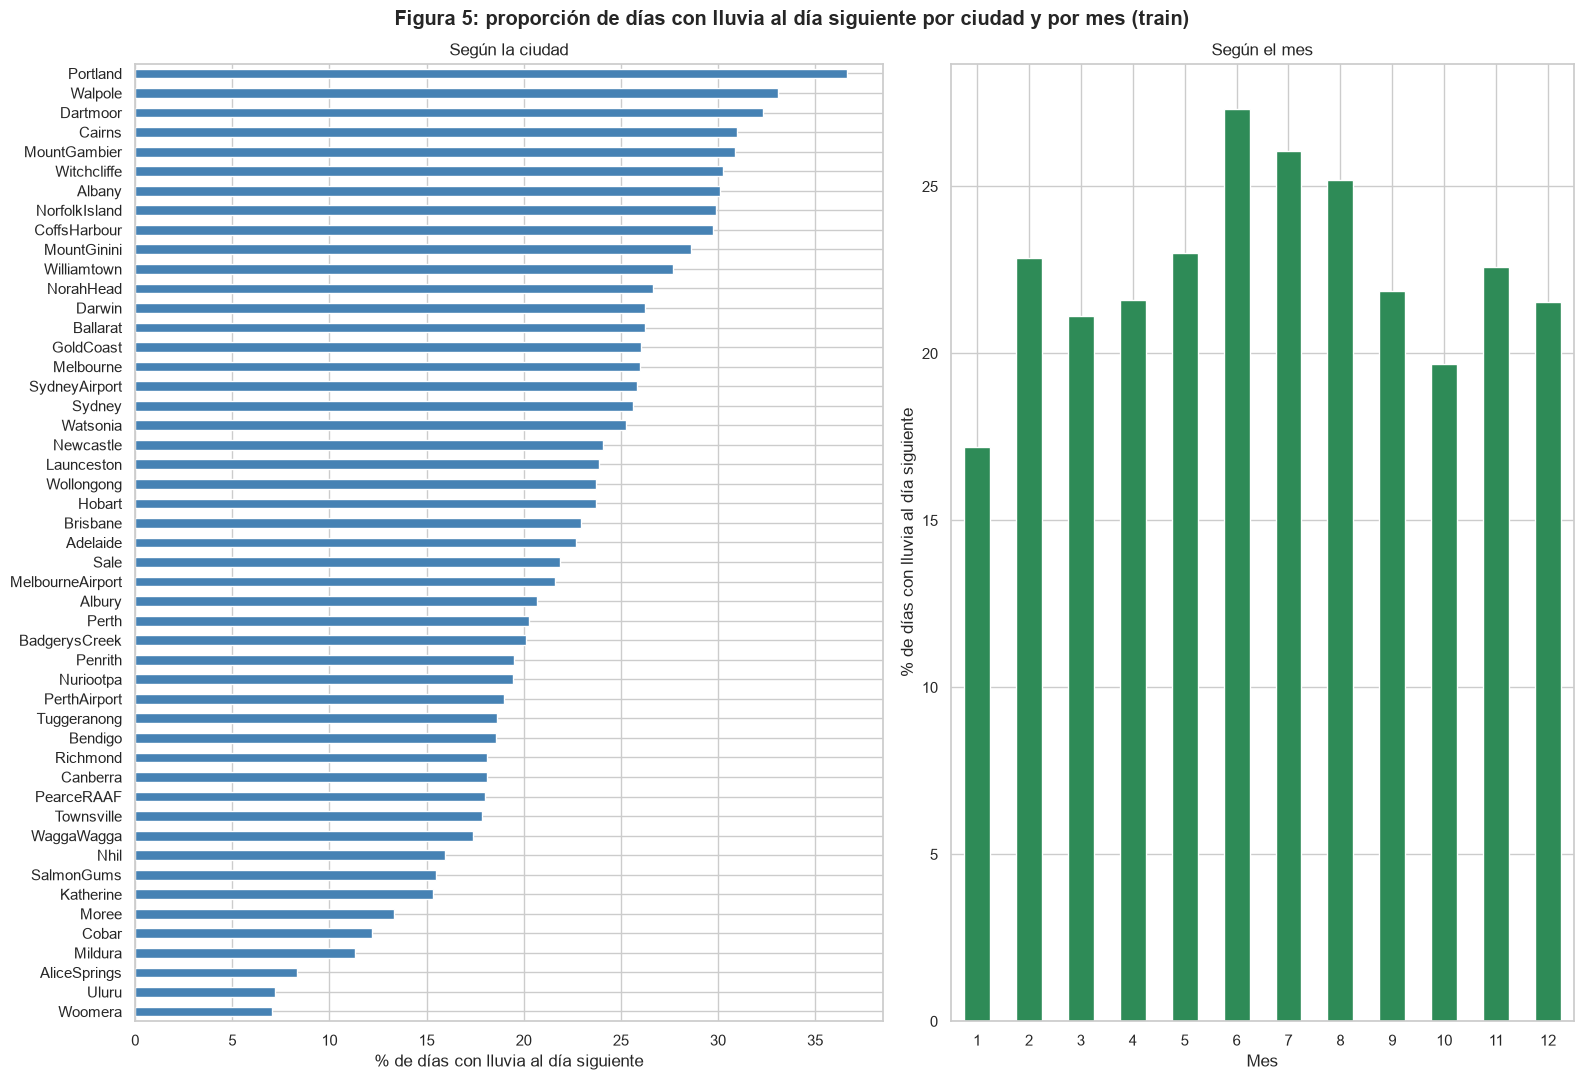

Por ciudad: entre 7.0% (Woomera) y 36.6% (Portland)
Por mes: entre 17.2% (mes 1) y 27.3% (mes 6)


In [23]:
# Figura 5: porcentaje de días con lluvia al día siguiente, según la ciudad y según el mes
lluvia_ciudad = train.groupby('Location')[TARGET].apply(lambda s: (s == 'Yes').mean() * 100).sort_values()
lluvia_mes = train.groupby(train['Date'].dt.month)[TARGET].apply(lambda s: (s == 'Yes').mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(16, 11), gridspec_kw={'width_ratios': [1.2, 1]})
lluvia_ciudad.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Según la ciudad')
axes[0].set_xlabel('% de días con lluvia al día siguiente')
axes[0].set_ylabel('')
lluvia_mes.plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title('Según el mes')
axes[1].set_xlabel('Mes')
axes[1].set_ylabel('% de días con lluvia al día siguiente')
axes[1].tick_params(axis='x', rotation=0)
fig.suptitle('Figura 5: proporción de días con lluvia al día siguiente por ciudad y por mes (train)', fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Por ciudad: entre {lluvia_ciudad.min():.1f}% ({lluvia_ciudad.idxmin()}) y {lluvia_ciudad.max():.1f}% ({lluvia_ciudad.idxmax()})')
print(f'Por mes: entre {lluvia_mes.min():.1f}% (mes {lluvia_mes.idxmin()}) y {lluvia_mes.max():.1f}% (mes {lluvia_mes.idxmax()})')

Figura 5: la proporción de días con lluvia al día siguiente cambia mucho según la ciudad, de 7,0% en Woomera a 36,6% en Portland, así que la ciudad aporta información. También cambia con el mes: es más alta en invierno (junio, julio y agosto, entre 25 y 27%) y más baja en enero (17,2%). La lluvia sube hacia el invierno y vuelve a bajar en verano, en un ciclo que se repite cada año, así que el mes se codifica respetando ese ciclo (sección 10).

---
## 8. Correlación

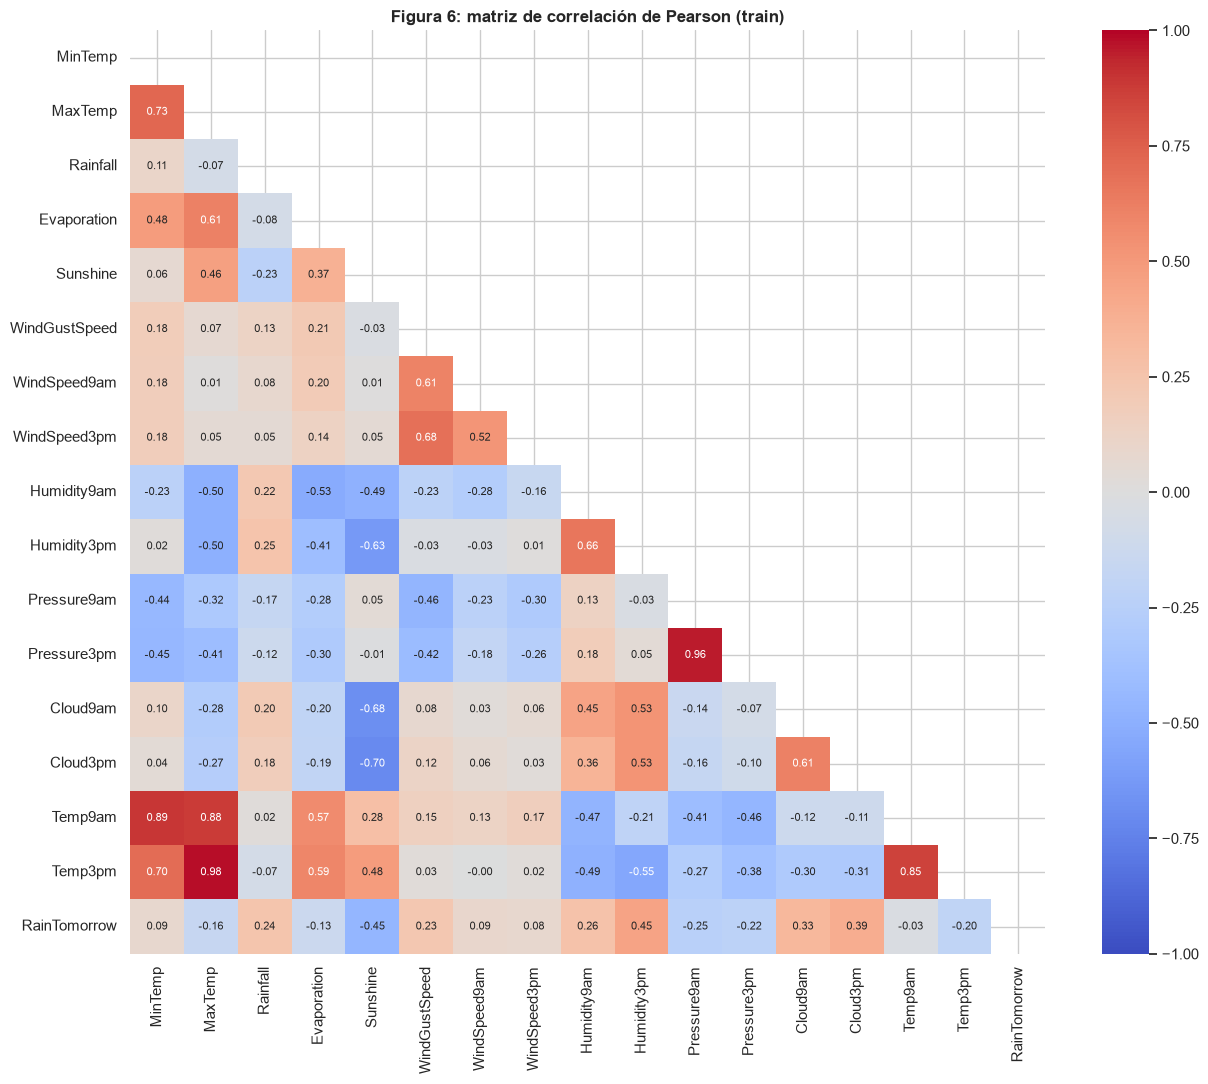

In [24]:
# Figura 6: matriz de correlación de Pearson entre las numéricas y el target pasado a 0/1
datos_corr = train[NUMERICAS].assign(RainTomorrow=(train[TARGET] == 'Yes').astype(int))
matriz_corr = datos_corr.corr()
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(matriz_corr, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            annot_kws={'size': 8}, ax=ax)
ax.set_title('Figura 6: matriz de correlación de Pearson (train)', fontweight='bold')
plt.tight_layout()
plt.show()

In [25]:
# Correlación de cada variable con el target: Pearson (lineal) y Spearman (orden)
pd.DataFrame({
    'Pearson': matriz_corr[TARGET].drop(TARGET),
    'Spearman': datos_corr.corr(method='spearman')[TARGET].drop(TARGET),
}).sort_values('Pearson', key=abs, ascending=False).round(3).T

,Sunshine,Humidity3pm,Cloud3pm,Cloud9am,Humidity9am,Pressure9am,Rainfall,WindGustSpeed,Pressure3pm,Temp3pm,MaxTemp,Evaporation,WindSpeed9am,MinTemp,WindSpeed3pm,Temp9am
Pearson,-0.454,0.448,0.393,0.329,0.260,-0.247,0.245,0.231,-0.224,-0.196,-0.164,-0.126,0.092,0.086,0.085,-0.027
Spearman,-0.442,0.434,0.406,0.336,0.270,-0.237,0.338,0.211,-0.214,-0.198,-0.163,-0.139,0.082,0.078,0.074,-0.032


In [26]:
# Pares de variables explicativas muy correlacionadas entre sí
UMBRAL_COLINEALIDAD = 0.85
corr_pearson = matriz_corr.drop(index=TARGET, columns=TARGET)

pares_colineales = []
for i in range(len(corr_pearson.columns)):
    for j in range(i + 1, len(corr_pearson.columns)):
        r = corr_pearson.iloc[i, j]
        if abs(r) >= UMBRAL_COLINEALIDAD:
            pares_colineales.append({'Variable 1': corr_pearson.columns[i], 'Variable 2': corr_pearson.columns[j], 'Pearson': r})

pd.DataFrame(pares_colineales).sort_values('Pearson', key=abs, ascending=False).reset_index(drop=True).round(3)

,Variable 1,Variable 2,Pearson
0,MaxTemp,Temp3pm,0.979
1,Pressure9am,Pressure3pm,0.959
2,MinTemp,Temp9am,0.894
3,MaxTemp,Temp9am,0.879
4,Temp9am,Temp3pm,0.852


Figura 6 y tablas:
- Las más relacionadas con la lluvia de mañana son `Sunshine` (−0,45), `Humidity3pm` (0,45) y la nubosidad (`Cloud3pm` 0,39 y `Cloud9am` 0,33), lo mismo que se veía en la Figura 2. Tres de esas cuatro son las que tienen más faltantes, por eso no las eliminamos sino que las imputamos.
- Pearson y Spearman dan parecido en casi todas. La excepción es `Rainfall` (0,25 contra 0,34), por lo asimétrica que es.
- Hay pares muy correlacionados entre sí: `Temp3pm` con `MaxTemp` (0,98), las dos presiones (0,96) y `Temp9am` con `MinTemp` (0,89). Casi repiten la misma información. Por ahora no sacamos ninguna: la regresión logística que vamos a usar tiene regularización, que reparte el peso entre variables parecidas.

---
## 9. Imputación de faltantes

Imputamos las variables numéricas con KNN: para cada día con faltantes se buscan los k días de train más parecidos según las otras variables, y cada faltante se completa con el promedio de esos k días. Como el faltante depende de la ciudad (sección 3), KNN puede usar días parecidos de otras ciudades cuando una ciudad nunca midió una variable.

El número de vecinos k hay que elegirlo. Para eso escondemos valores que sí conocemos, los imputamos con distintos k y comparamos contra el valor real. Como referencia agregamos el error de completar todo con la mediana de train, que es la forma más simple de imputar.

In [27]:
# Completa las numéricas de datos con KNN, buscando los vecinos en base
def imputar_knn(base, datos, k, filas_base=20000):
    # KNN usa distancias: escalamos solo para imputar y después volvemos a las unidades originales.
    # Como vecinos usa una muestra de 20000 días de la base, para que no tarde demasiado
    escala = StandardScaler().fit(base[NUMERICAS])
    vecinos = base[NUMERICAS].sample(min(filas_base, len(base)), random_state=42)
    imputador = KNNImputer(n_neighbors=k).fit(escala.transform(vecinos))
    completo = datos.copy()
    completo[NUMERICAS] = escala.inverse_transform(imputador.transform(escala.transform(datos[NUMERICAS])))
    return completo

In [28]:
# Escondemos el 20% de los valores conocidos de cada variable en 20000 días de train
# Cada variable usa otra semilla, para que no se escondan siempre los mismos días
muestra_exp = train.sample(20000, random_state=42)
oculta = muestra_exp.copy()
escondidos = {}
for i, col in enumerate(NUMERICAS):
    escondidos[col] = muestra_exp[col].dropna().sample(frac=0.2, random_state=i).index
    oculta.loc[escondidos[col], col] = np.nan

# La base de KNN no puede ver los valores escondidos
base_oculta = train.copy()
base_oculta.loc[oculta.index, NUMERICAS] = oculta[NUMERICAS]

def rmse(imputado, col):
    return np.sqrt(mean_squared_error(muestra_exp.loc[escondidos[col], col], imputado.loc[escondidos[col], col]))

# Error de cada variable con la mediana y con KNN para distintos k
con_mediana = oculta.fillna(base_oculta[NUMERICAS].median())
errores = pd.DataFrame({'Mediana': [rmse(con_mediana, c) for c in NUMERICAS]}, index=NUMERICAS)
for k in [5, 10, 20, 30, 50]:
    con_knn = imputar_knn(base_oculta, oculta, k)
    errores[f'k = {k}'] = [rmse(con_knn, c) for c in NUMERICAS]
errores.round(2)

,Mediana,k = 5,k = 10,k = 20,k = 30,k = 50
MinTemp,6.370,5.330,4.450,3.880,3.650,3.470
MaxTemp,7.000,6.290,5.270,4.050,3.580,3.190
Rainfall,9.090,8.940,8.440,8.250,8.190,8.120
Evaporation,3.920,2.960,2.790,2.720,2.680,2.660
Sunshine,3.990,3.090,2.660,2.470,2.420,2.380
WindGustSpeed,14.080,12.810,11.870,11.220,10.980,10.790
WindSpeed9am,9.090,8.820,8.220,7.880,7.730,7.600
WindSpeed3pm,8.860,8.930,8.210,7.840,7.670,7.520
Humidity9am,18.940,16.800,14.790,13.770,13.400,13.150
Humidity3pm,21.070,16.980,15.320,14.200,13.800,13.560


In [29]:
# Porcentaje en que KNN baja el error respecto de la mediana, por variable y en promedio
mejora = pd.DataFrame(index=NUMERICAS)
for k in [5, 10, 20, 30, 50]:
    mejora[f'k = {k}'] = (errores['Mediana'] - errores[f'k = {k}']) / errores['Mediana'] * 100
print(f'Variables donde la mediana tiene menos error que KNN con k = 20: {list(errores.index[errores["Mediana"] < errores["k = 20"]])}')
mejora.loc['Promedio'] = mejora.mean()
mejora.round(1)

Variables donde la mediana tiene menos error que KNN con k = 20: []


,k = 5,k = 10,k = 20,k = 30,k = 50
MinTemp,16.400,30.100,39.100,42.700,45.600
MaxTemp,10.200,24.700,42.100,48.900,54.500
Rainfall,1.600,7.100,9.200,9.900,10.600
Evaporation,24.300,28.600,30.400,31.600,32.000
Sunshine,22.600,33.300,38.200,39.500,40.400
WindGustSpeed,9.000,15.700,20.300,22.100,23.400
WindSpeed9am,3.000,9.600,13.300,15.000,16.400
WindSpeed3pm,-0.800,7.300,11.500,13.400,15.100
Humidity9am,11.300,21.900,27.300,29.200,30.600
Humidity3pm,19.400,27.300,32.600,34.500,35.700


Elegimos k = 20.
- Con k = 20, KNN tiene menos error que la mediana en las 16 variables y lo baja un 31,1% en promedio. Donde más mejora es en las temperaturas (entre 39,1% y 56,7%) y donde menos en la lluvia y el viento (entre 9,2% y 20,3%).
- El error baja a medida que sube k, pero cada vez menos: la mejora pasa de 18,4% con k = 5 a 26,1% con k = 10 y 31,1% con k = 20, y después solo a 33,1% con k = 30 y 34,6% con k = 50. Elegimos 20 porque hasta ahí cada paso suma 5 puntos o más, y desde ahí 2 o menos.
- No tomamos un k más grande porque, al promediar cada vez más días, el valor imputado se parece cada vez más a un promedio general y pierde lo particular de ese día.
- Creemos que convienen tantos vecinos porque muchos días tienen varias variables faltantes y la distancia se calcula solo con las que hay, entonces los vecinos más cercanos no siempre son tan parecidos.

Las direcciones del viento son categorías y KNN no las puede promediar: esas se completan con la dirección más frecuente de la ciudad en train.

In [30]:
# Imputación definitiva: KNN con k = 20, buscando los vecinos siempre en train
inicio = time.time()
train_imp = imputar_knn(train, train, 20)
val_imp = imputar_knn(train, val, 20)
test_imp = imputar_knn(train, test, 20)
print(f'Tiempo de imputación: {time.time() - inicio:.0f} segundos')

Tiempo de imputación: 105 segundos


In [31]:
# Ajustes después de imputar: nubosidad en octas enteras, RainToday según la lluvia y el viento con la moda de la ciudad
VIENTO = ['WindGustDir', 'WindDir9am', 'WindDir3pm']
moda_ciudad = train.groupby('Location')[VIENTO].agg(lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
moda_general = train[VIENTO].mode().iloc[0]

def completar(datos):
    completo = datos.copy()
    completo[['Cloud9am', 'Cloud3pm']] = completo[['Cloud9am', 'Cloud3pm']].round().clip(0, 8)
    completo['RainToday'] = np.where(completo['Rainfall'] > 1, 'Yes', 'No')
    for col in VIENTO:
        completo[col] = completo[col].fillna(completo['Location'].map(moda_ciudad[col])).fillna(moda_general[col])
    return completo

train_imp, val_imp, test_imp = completar(train_imp), completar(val_imp), completar(test_imp)
pd.DataFrame({'Faltantes antes': [d.isna().sum().sum() for d in (train, val, test)],
              'Faltantes después': [d.isna().sum().sum() for d in (train_imp, val_imp, test_imp)]},
             index=list(conjuntos))

,Faltantes antes,Faltantes después
Train,200993,0
Validación,40893,0
Test,74559,0


No quedan faltantes en ningún conjunto. Después de imputar redondeamos la nubosidad a octas enteras, recalculamos `RainToday` a partir de la lluvia (regla de la sección 4) y completamos las direcciones del viento.

---
## 10. Codificación de variables categóricas

- `RainTomorrow` y `RainToday` pasan a 1 (Yes) y 0 (No).
- De la fecha nos quedamos con el mes, porque la proporción de lluvia cambia según la época del año (Figura 5). La fecha completa no se usa como variable.
- `Location` es una categoría sin ningún orden: no tiene sentido decir que "Sydney" es mayor que "Perth". La pasamos a one-hot, una columna 0/1 por ciudad. Con `drop_first=True` se saca una, porque queda determinada por las demás.

El mes y las direcciones de viento son distintos: tienen un orden, pero es circular. Después de diciembre viene enero, y la brújula va de N a NNE, NE, E y sigue girando hasta NNW, que vuelve a estar al lado de N. Si los numeráramos (enero = 1 ... diciembre = 12, N = 0 ... NNW = 15), diciembre y enero quedarían en los extremos, como si fueran los meses más distintos, cuando en realidad son vecinos. Con one-hot el problema del orden desaparece, pero se pierde la idea de que hay meses y direcciones vecinas, y hacen falta 11 columnas para el mes y 15 para cada dirección de viento.

Por eso los codificamos de forma cíclica, como las agujas de un reloj: cada mes y cada dirección es un punto sobre un círculo, y lo guardamos con dos columnas, el seno y el coseno de su ángulo. Así diciembre queda al lado de enero y NNW al lado de N. Cada variable pasa a ocupar 2 columnas en lugar de 11 o 15, el modelo queda más simple y se lee mejor: con los dos coeficientes de cada variable se ve hacia qué época del año o hacia qué dirección del viento aumenta la probabilidad de lluvia.

In [32]:
# Codificación de los tres conjuntos: ciudad con one-hot, mes y viento como ángulos de un círculo
ORDEN_VIENTO = {'N': 0, 'NNE': 1, 'NE': 2, 'ENE': 3, 'E': 4, 'ESE': 5, 'SE': 6, 'SSE': 7,
                'S': 8, 'SSW': 9, 'SW': 10, 'WSW': 11, 'W': 12, 'WNW': 13, 'NW': 14, 'NNW': 15}

def codificar(datos):
    codificado = datos.copy()
    codificado[TARGET] = (codificado[TARGET] == 'Yes').astype(int)
    codificado['RainToday'] = (codificado['RainToday'] == 'Yes').astype(int)
    # El mes da una vuelta completa en 12 pasos
    mes = codificado['Date'].dt.month
    codificado['Mes_sin'] = np.sin(2 * np.pi * mes / 12)
    codificado['Mes_cos'] = np.cos(2 * np.pi * mes / 12)
    # La brújula da una vuelta completa en 16 direcciones
    for col in VIENTO:
        angulo = 2 * np.pi * codificado[col].map(ORDEN_VIENTO) / 16
        codificado[col + '_sin'] = np.sin(angulo)
        codificado[col + '_cos'] = np.cos(angulo)
    codificado = codificado.drop(columns=['Date'] + VIENTO)
    codificado = pd.get_dummies(codificado, columns=['Location'], drop_first=True, dtype=int)
    return codificado

train_cod = codificar(train_imp)
val_cod = codificar(val_imp)
test_cod = codificar(test_imp)
print(f'Mismas columnas que train: validación {list(val_cod.columns) == list(train_cod.columns)} | test {list(test_cod.columns) == list(train_cod.columns)}')

X_train, y_train = train_cod.drop(columns=TARGET), train_cod[TARGET]
X_val, y_val = val_cod.drop(columns=TARGET), val_cod[TARGET]
X_test, y_test = test_cod.drop(columns=TARGET), test_cod[TARGET]

print(f'Variables después de codificar: {X_train.shape[1]}')
print(f'  Location: {sum(c.startswith("Location_") for c in X_train.columns)} columnas')
print(f'  Mes y viento: {[c for c in X_train.columns if c.endswith(("_sin", "_cos"))]}')
print(f'Train {X_train.shape} | Validación {X_val.shape} | Test {X_test.shape}')

Mismas columnas que train: validación True | test True
Variables después de codificar: 73
  Location: 48 columnas
  Mes y viento: ['Mes_sin', 'Mes_cos', 'WindGustDir_sin', 'WindGustDir_cos', 'WindDir9am_sin', 'WindDir9am_cos', 'WindDir3pm_sin', 'WindDir3pm_cos']
Train (98988, 73) | Validación (17231, 73) | Test (25934, 73)


In [33]:
# Ejemplo: meses y direcciones vecinas quedan con seno y coseno parecidos
meses = np.array([11, 12, 1, 2, 6])
vientos = ['NNW', 'N', 'NNE', 'S']
angulos = list(2 * np.pi * meses / 12) + [2 * np.pi * ORDEN_VIENTO[d] / 16 for d in vientos]
ejemplo = pd.DataFrame({'Seno': np.sin(angulos), 'Coseno': np.cos(angulos)},
                       index=['Noviembre', 'Diciembre', 'Enero', 'Febrero', 'Junio'] + ['Viento ' + d for d in vientos])
ejemplo.round(2).T

,Noviembre,Diciembre,Enero,Febrero,Junio,Viento NNW,Viento N,Viento NNE,Viento S
Seno,-0.500,-0.000,0.500,0.870,0.000,-0.380,0.000,0.380,0.000
Coseno,0.870,1.000,0.870,0.500,-1.000,0.920,1.000,0.920,-1.000


Diciembre (seno 0, coseno 1) queda entre noviembre y enero, que tienen valores parecidos, y junio, en la otra punta del año, queda en el lado opuesto del círculo (coseno −1). Con el viento pasa lo mismo: NNW y NNE quedan a los dos lados de N, y S queda enfrente. Con estas columnas el modelo pasa de 121 a 73 variables.

---
## 11. Escalado

Las variables numéricas tienen escalas muy distintas (la presión ronda los 1000 hPa y la nubosidad va de 0 a 8; ver la tabla de la sección 7). La regresión logística se ajusta con un método iterativo que converge mejor cuando están en escalas parecidas, y su regularización penaliza el tamaño de los coeficientes, que depende de las unidades de cada variable. Usamos `StandardScaler` sobre las 16 numéricas, ajustado con train. Las columnas one-hot y `RainToday` ya son 0/1, y los senos y cosenos ya están entre −1 y 1, así que quedan como están.

In [34]:
# Escalado de las numéricas con la media y el desvío de train
scaler = StandardScaler().fit(X_train[NUMERICAS])
X_train_esc, X_val_esc, X_test_esc = X_train.copy(), X_val.copy(), X_test.copy()
for X in (X_train_esc, X_val_esc, X_test_esc):
    X[NUMERICAS] = scaler.transform(X[NUMERICAS])

# Control: en train cada numérica queda con media 0 y desvío 1
pd.DataFrame({'Media': X_train_esc[NUMERICAS].mean(), 'Desvío': X_train_esc[NUMERICAS].std()}).round(2).T

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
Media,-0.000,-0.000,0.000,-0.000,0.000,-0.000,-0.000,-0.000,0.000,0.000,0.000,-0.000,-0.000,-0.000,-0.000,0.000
Desvío,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


Resumen del ítem 1: partimos de 145.412 filas y 25 columnas. Sacamos `RainfallTomorrow`, que es información del futuro, y el número de fila; eliminamos las 3259 filas sin target y dividimos por fecha en train (hasta 2014), validación (2015) y test (desde 2016). Imputamos las numéricas con KNN y el viento con la moda de cada ciudad, codificamos la ciudad con one-hot y el mes y el viento de forma cíclica, y escalamos las numéricas. Quedan 73 variables y un target desbalanceado (22,5% de días con lluvia en train), que es lo que hay que tener en cuenta al elegir las métricas del ítem 2.

---
# Ítem 2. Regresión logística

## 12. Entrenamiento de los modelos

Entrenamos dos regresiones logísticas con las 73 variables escaladas:

- Sin pesos: todos los días valen lo mismo al ajustar el modelo.
- Balanceada (`class_weight='balanced'`): los errores en los días de lluvia pesan más, en proporción inversa a cuántos hay. Con 22,5% de días "Yes", un error en un día de lluvia pesa unas 3,4 veces más que uno en un día sin lluvia. La idea es compensar el desbalance de la sección 6.

In [35]:
# Entrenamos los dos modelos con train
modelos = {
    'Sin pesos': LogisticRegression(random_state=42),
    'Balanceada': LogisticRegression(random_state=42, class_weight='balanced'),
}
for nombre, modelo in modelos.items():
    modelo.fit(X_train_esc, y_train)
    # Control: converge antes del máximo de 100 iteraciones que trae por defecto
    print(f'{nombre}: {modelo.n_iter_[0]} iteraciones hasta converger')

pesos = len(y_train) / (2 * y_train.value_counts())
print(f'Pesos de la balanceada: No {pesos[0]:.2f} | Yes {pesos[1]:.2f} (un error en Yes pesa {pesos[1] / pesos[0]:.1f} veces más)')

Sin pesos: 97 iteraciones hasta converger


Balanceada: 90 iteraciones hasta converger
Pesos de la balanceada: No 0.65 | Yes 2.22 (un error en Yes pesa 3.4 veces más)


---
## 13. Métricas

La clase positiva es "Yes" (llueve mañana). Además de accuracy, precision, recall y F1, calculamos dos métricas que no dependen del umbral de 0,5, porque usan las probabilidades:

- AUC ROC: el área bajo la curva ROC (sección 15). Mide qué tan bien el modelo ordena los días: si toma un día de lluvia y uno sin lluvia al azar, es la probabilidad de que le dé más probabilidad de lluvia al primero. 0,5 es azar y 1 es perfecto.
- AUC PR: el área bajo la curva precision-recall. Se fija solo en la clase "Yes", así que con datos desbalanceados es más exigente que la anterior. Un modelo al azar daría la proporción de días con lluvia (0,23).

In [36]:
# Métricas de la clase Yes en train, validación y test, con el umbral de 0,5
conjuntos_esc = {'Train': (X_train_esc, y_train), 'Validación': (X_val_esc, y_val), 'Test': (X_test_esc, y_test)}
prob = {}
filas = []
for nombre, modelo in modelos.items():
    prob[nombre] = {}
    for conj, (X, y) in conjuntos_esc.items():
        # Probabilidad de lluvia de cada día
        prob[nombre][conj] = modelo.predict_proba(X)[:, 1]
        y_pred = (prob[nombre][conj] >= 0.5).astype(int)
        precision_c, recall_c, _ = precision_recall_curve(y, prob[nombre][conj])
        filas.append({'Modelo': nombre, 'Conjunto': conj,
                      'Accuracy': accuracy_score(y, y_pred), 'Precision': precision_score(y, y_pred),
                      'Recall': recall_score(y, y_pred), 'F1': f1_score(y, y_pred),
                      'AUC ROC': roc_auc_score(y, prob[nombre][conj]), 'AUC PR': auc(recall_c, precision_c)})

tabla_metricas = pd.DataFrame(filas).set_index(['Modelo', 'Conjunto'])
tabla_metricas.round(3)

Accuracy  Precision  Recall    F1  AUC ROC  AUC PR
Modelo     Conjunto                                                      
Sin pesos  Train          0.851      0.731   0.534 0.617    0.877   0.717
           Validación     0.855      0.739   0.491 0.590    0.877   0.702
           Test           0.844      0.720   0.526 0.608    0.862   0.697
Balanceada Train          0.798      0.536   0.784 0.637    0.878   0.714
           Validación     0.813      0.543   0.749 0.629    0.878   0.700
           Test           0.791      0.530   0.768 0.627    0.863   0.694

In [37]:
# Reporte de las dos clases en test
for nombre in modelos:
    y_pred = (prob[nombre]['Test'] >= 0.5).astype(int)
    print(f'Resultados de la regresión logística {nombre.lower()} en test\n')
    print(classification_report(y_test, y_pred, target_names=['No', 'Yes'], digits=3))

Resultados de la regresión logística sin pesos en test

              precision    recall  f1-score   support

          No      0.869     0.939     0.903     19993
         Yes      0.720     0.526     0.608      5941

    accuracy                          0.844     25934
   macro avg      0.795     0.732     0.755     25934
weighted avg      0.835     0.844     0.835     25934

Resultados de la regresión logística balanceada en test

              precision    recall  f1-score   support

          No      0.920     0.798     0.855     19993
         Yes      0.530     0.768     0.627      5941

    accuracy                          0.791     25934
   macro avg      0.725     0.783     0.741     25934
weighted avg      0.831     0.791     0.803     25934



Tabla de métricas, en test:
- El modelo sin pesos tiene la mejor accuracy (0,844), pero detecta solo el 52,6% de los días de lluvia (recall). Cuando dice que llueve acierta bastante (precision 0,720). Es el efecto del desbalance: el modelo se inclina hacia "No", que es lo más frecuente.
- La balanceada detecta el 76,8% de los días de lluvia, a cambio de más falsas alarmas (precision 0,530). Su accuracy baja a 0,791 porque se equivoca más en los días sin lluvia (su recall de "No" pasa de 0,939 a 0,798), que son la mayoría. En F1 queda algo mejor (0,627 contra 0,608).
- Las dos AUC son prácticamente iguales en los dos modelos (ROC 0,862 y 0,863; PR 0,697 y 0,694). O sea que los dos ordenan los días casi igual por probabilidad de lluvia, y lo que cambia es dónde cae el umbral de 0,5.
- La AUC PR de 0,70 está muy por encima del 0,23 que daría un modelo al azar.

---
## 14. Matrices de confusión

Cada matriz cuenta los aciertos y errores en test. Las filas son lo que pasó y las columnas lo que predijo el modelo:

- Falso positivo (FP): dijimos que llovía y no llovió.
- Falso negativo (FN): dijimos que no llovía y llovió.

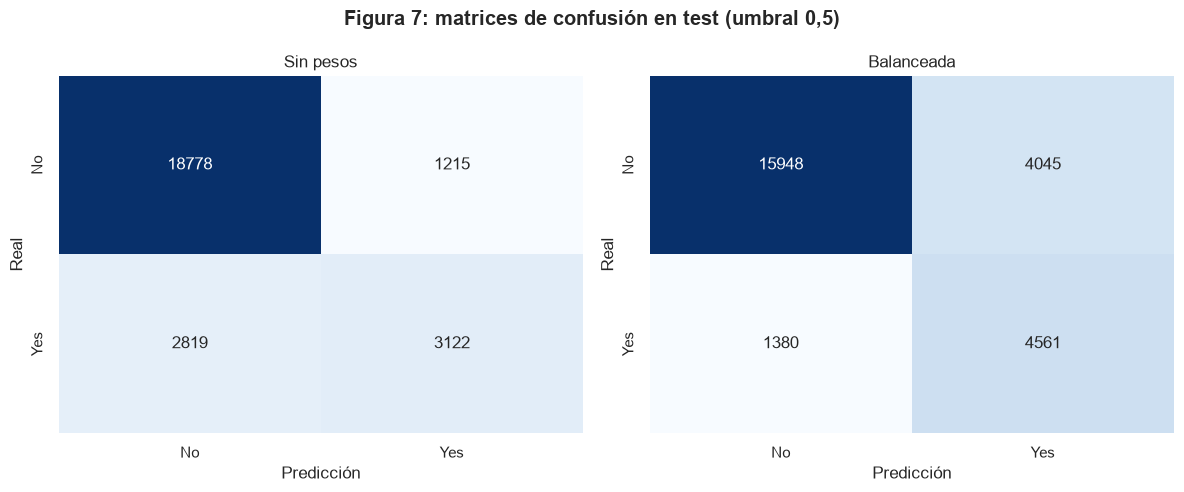

In [38]:
# Figura 7: matrices de confusión en test de los dos modelos, con el umbral de 0,5
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, nombre in zip(axes, modelos):
    matriz = confusion_matrix(y_test, (prob[nombre]['Test'] >= 0.5).astype(int))
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    ax.set_title(nombre)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Real')
fig.suptitle('Figura 7: matrices de confusión en test (umbral 0,5)', fontweight='bold')
plt.tight_layout()
plt.show()

Figura 7: el modelo sin pesos tiene 2819 falsos negativos y 1215 falsos positivos; la balanceada baja los falsos negativos a la mitad (1380) pero más que triplica los falsos positivos (4045).

Para un pronóstico de lluvia nos parece peor el falso negativo, porque la persona no se prepara para la lluvia. Pero si el pronóstico anuncia lluvia muy seguido y después no llueve, también deja de servir. Por eso buscamos un equilibrio entre los dos errores y usamos el F1 para elegir el umbral (sección 15).

---
## 15. Curva ROC y elección del umbral

El modelo da una probabilidad de lluvia, y el umbral es el valor a partir del cual decimos "Yes". La curva ROC muestra, para cada umbral posible, la proporción de días de lluvia detectados (TPR, que es el recall) contra la proporción de días sin lluvia en los que dimos una falsa alarma (FPR). La armamos con validación, porque el umbral es una decisión y no se puede tomar mirando test.

Probamos dos formas de elegir el umbral:

- Índice de Youden: el umbral donde la diferencia TPR − FPR es máxima, es decir el punto de la curva más alejado de la diagonal del azar.
- Máximo F1: el umbral con mejor F1, que equilibra precision y recall.

In [39]:
# Umbrales elegidos en validación para cada modelo
umbrales_prueba = np.arange(0.05, 0.95, 0.01)
umbrales = {}
for nombre in modelos:
    p_val = prob[nombre]['Validación']
    # Youden: el umbral donde TPR - FPR es máximo
    fpr, tpr, thresholds = roc_curve(y_val, p_val)
    youden = thresholds[np.argmax(tpr - fpr)]
    # Máximo F1: probamos umbrales de 0,05 a 0,94 y nos quedamos con el de mayor F1
    f1_val = [f1_score(y_val, (p_val >= u).astype(int)) for u in umbrales_prueba]
    umbrales[nombre] = {'Youden': youden, 'Máximo F1': umbrales_prueba[np.argmax(f1_val)]}
pd.DataFrame(umbrales).round(3)

,Sin pesos,Balanceada
Youden,0.224,0.448
Máximo F1,0.250,0.540


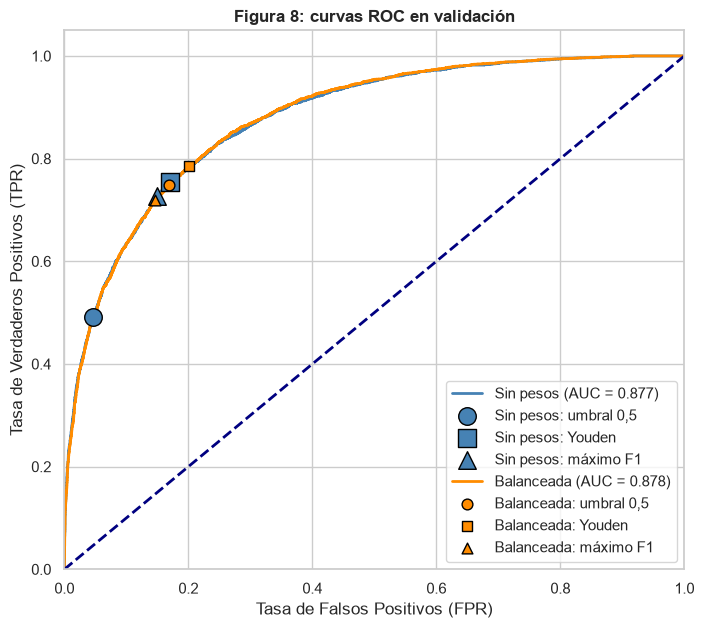

In [40]:
# Figura 8: curvas ROC en validación, con el punto que da cada umbral
plt.figure(figsize=(8, 7))
for nombre, color, tam in zip(modelos, ['steelblue', 'darkorange'], [160, 60]):
    p_val = prob[nombre]['Validación']
    fpr, tpr, thresholds = roc_curve(y_val, p_val)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{nombre} (AUC = {roc_auc:.3f})')
    for criterio, umbral, marcador in [('umbral 0,5', 0.5, 'o'), ('Youden', umbrales[nombre]['Youden'], 's'),
                                       ('máximo F1', umbrales[nombre]['Máximo F1'], '^')]:
        vn, fp, fn, vp = confusion_matrix(y_val, (p_val >= umbral).astype(int)).ravel()
        plt.scatter(fp / (fp + vn), vp / (vp + fn), color=color, marker=marcador, s=tam, edgecolor='black', zorder=3,
                    label=f'{nombre}: {criterio}')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Figura 8: curvas ROC en validación', fontweight='bold')
plt.legend(loc='lower right')
plt.show()

Figura 8: las dos curvas ROC están una encima de la otra (AUC 0,877 y 0,878). Darle más peso a los días de lluvia no cambia cómo el modelo ordena los días, solo sube todas las probabilidades, y eso corre los puntos sobre la misma curva. El umbral de 0,5 de la balanceada (círculo naranja) cae casi donde está el Youden del modelo sin pesos (cuadrado azul).

Los umbrales elegidos en validación son muy distintos de 0,5: para el modelo sin pesos, 0,224 con Youden y 0,250 con máximo F1. En la balanceada, 0,448 y 0,540, porque sus probabilidades ya vienen corridas hacia arriba.

In [41]:
# Cada modelo en test con el umbral de 0,5 y con los umbrales elegidos en validación
filas = []
for nombre in modelos:
    p_test = prob[nombre]['Test']
    for criterio, umbral in [('0,5', 0.5), ('Youden', umbrales[nombre]['Youden']), ('Máximo F1', umbrales[nombre]['Máximo F1'])]:
        y_pred = (p_test >= umbral).astype(int)
        vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()
        filas.append({'Modelo': nombre, 'Criterio': criterio, 'Umbral': umbral,
                      'Accuracy': accuracy_score(y_test, y_pred), 'Precision': precision_score(y_test, y_pred),
                      'Recall': recall_score(y_test, y_pred), 'F1': f1_score(y_test, y_pred), 'FP': fp, 'FN': fn})

pd.DataFrame(filas).set_index(['Modelo', 'Criterio']).round(3)

Umbral  Accuracy  Precision  Recall    F1    FP    FN
Modelo     Criterio                                                        
Sin pesos  0,5         0.500     0.844      0.720   0.526 0.608  1215  2819
           Youden      0.224     0.789      0.527   0.770 0.625  4111  1367
           Máximo F1   0.250     0.802      0.549   0.746 0.633  3637  1510
Balanceada 0,5         0.500     0.791      0.530   0.768 0.627  4045  1380
           Youden      0.448     0.768      0.496   0.799 0.612  4818  1193
           Máximo F1   0.540     0.804      0.553   0.742 0.634  3559  1533

Con los umbrales elegidos en validación y aplicados a test:
- 0,5 no es el mejor umbral para el modelo sin pesos. Bajándolo a 0,250 (máximo F1) el recall sube de 0,526 a 0,746, la precision baja de 0,720 a 0,549 y el F1 mejora de 0,608 a 0,633. Los falsos negativos bajan de 2819 a 1510.
- Youden da un umbral parecido (0,224): detecta algo más (recall 0,770), pero con 4111 falsas alarmas contra 3637, y su F1 queda un poco más abajo (0,625).
- Con su umbral de máximo F1, los dos modelos quedan prácticamente iguales (F1 0,633 y 0,634, con cantidades de FP y FN parecidas). Si se elige bien el umbral, los pesos no cambian el resultado.

Nos quedamos con la regresión logística sin pesos y umbral 0,250, elegido en validación con el máximo F1. En test: accuracy 0,802, precision 0,549, recall 0,746 y F1 0,633. Es el modelo que comparamos con el modelo base en el ítem 3.

---
## 16. Calidad del ajuste

Para ver el ajuste comparamos las métricas de train, validación y test de la tabla de la sección 13:
- No hay sobreajuste. En el modelo sin pesos, la AUC ROC es 0,877 en train, 0,877 en validación y 0,862 en test, y la AUC PR 0,717, 0,702 y 0,697. Si el modelo hubiera memorizado train, la caída sería mucho mayor. Es esperable, porque son 73 variables contra casi 99.000 días y la regresión logística de sklearn ya trae regularización.
- La pequeña caída en test puede venir de que ahí hay muchos más valores imputados (`Sunshine` falta en el 69% de test contra el 41% de train, sección 5).

Consideramos que el ajuste es bueno porque lo que mide en validación se mantiene en test.